# CXAS on the Imaging Data Commons: DICOM in, DICOM out

`cxas_idc` reads DICOM radiographs and writes, per image:
- `seg.dcm`: one DICOM Segmentation with every structure, at full resolution,
- `landmarks_sr.dcm`: a DICOM Structured Report (TID 1500) with the landmarks and measurements,
- `result.json`: the same as plain JSON.

Both DICOM objects reference the source image, so viewers and the [NCI Imaging Data Commons](https://portal.imaging.datacommons.cancer.gov/)
(IDC) show them on top of it. This notebook finds chest radiographs in IDC, runs CXAS and reads the results back with
[highdicom](https://github.com/ImagingDataCommons/highdicom).

In [1]:
# !pip install cxas idc-index highdicom pylibjpeg pylibjpeg-openjpeg   # pylibjpeg: decodes the JPEG 2000 SEG

## Find chest radiographs in IDC

`idc-index` ships the IDC metadata as a local table that can be queried with SQL, no account needed.

In [2]:
import warnings; warnings.filterwarnings("ignore")
import transformers; transformers.utils.logging.disable_progress_bar()
import matplotlib.pyplot as plt; plt.rcParams["figure.dpi"] = 72
from idc_index import IDCClient

idc = IDCClient()
print("IDC version", idc.get_idc_version())
idc.sql_query("""
    SELECT collection_id, license_short_name AS license, COUNT(*) AS series,
           ROUND(SUM(series_size_MB) / 1024, 1) AS size_GB
    FROM index
    WHERE Modality IN ('CR', 'DX') AND BodyPartExamined = 'CHEST'
    GROUP BY 1, 2 ORDER BY series DESC LIMIT 8""")

IDC version v25


,collection_id,license,series,size_GB
0,covid_19_ny_sbu,CC BY 4.0,13643,203.9
1,midrc_ricord_1c,CC BY-NC 4.0,1164,11.2
2,lidc_idri,CC BY 3.0,290,4.6
3,covid_19_ar,CC BY 4.0,256,3.1
4,varepop_apollo,CC BY 4.0,43,0.7
5,cmb_mml,CC BY 4.0,27,0.3
6,acrin_nsclc_fdg_pet,CC BY 3.0,24,0.4
7,rider_pilot,CC BY 4.0,22,0.4


Check the license per collection: most are CC BY, some (e.g. `midrc_ricord_1c`) are CC BY-NC. Here we use three CC BY images (`demo_utils.py` has the series UIDs and citations); `idc.download_from_selection(...)` does the download.

In [3]:
from demo_utils import get_example_images, display_image, overlay
paths = get_example_images()
dicoms = [paths["frontal_pa"], paths["lateral"], paths["frontal_ap_portable"]]
dicoms

['example_data/frontal_pa.dcm',
 'example_data/lateral.dcm',
 'example_data/frontal_ap_portable.dcm']

## Run CXAS

The same command runs in the Docker image, which has all models inside:

```bash
docker run --rm -v $PWD/example_data:/data/in:ro -v $PWD/out/idc:/data/out cseibold/cxas:0.1.2-cpu -i /data/in -o /data/out
```

In [4]:
import subprocess, sys, os, shutil

device = "auto"     # GPU 0 if available, else CPU
cxas_idc = shutil.which("cxas_idc") or os.path.join(os.path.dirname(sys.executable), "cxas_idc")
log = subprocess.run([cxas_idc, "-i", *dicoms, "-o", "out/idc", "-g", device], capture_output=True, text=True, check=True)
print("\n".join(l for l in log.stdout.splitlines() if l.strip()))

device: cpu
example_data/frontal_pa.dcm: view=frontal structures=178 landmarks=201/203 7.3s
example_data/lateral.dcm: view=lateral structures=91 landmarks=100/108 5.9s
example_data/frontal_ap_portable.dcm: view=frontal structures=179 landmarks=200/203 12.2s
done: 3 ok, 0 failed


In [5]:
import glob, json

results = {os.path.relpath(json.load(open(p))["input"]): os.path.dirname(p) for p in glob.glob("out/idc/*/result.json")}
for src, folder in results.items():
    print(os.path.basename(src), "->", folder, sorted(os.listdir(folder)))

frontal_ap_portable.dcm -> out/idc/1.3.6.1.4.1.14519.5.2.1.99.1071.33585871997107358488394652161423 ['landmarks_sr.dcm', 'result.json', 'seg.dcm']
frontal_pa.dcm -> out/idc/1.3.6.1.4.1.14519.5.2.1.6279.6001.259024827419628700387407156445 ['landmarks_sr.dcm', 'result.json', 'seg.dcm']
lateral.dcm -> out/idc/1.3.6.1.4.1.14519.5.2.1.6279.6001.203849802556601198380234975276 ['landmarks_sr.dcm', 'result.json', 'seg.dcm']


## Read the DICOM Segmentation

In [6]:
import highdicom as hd
import pydicom

src = paths["frontal_ap_portable"]
source = pydicom.dcmread(src, stop_before_pixels=True)
seg = hd.seg.segread(os.path.join(results[src], "seg.dcm"))

ref = seg.ReferencedSeriesSequence[0]
print("references the source series:", ref.SeriesInstanceUID == source.SeriesInstanceUID)
print("references the source image: ", ref.ReferencedInstanceSequence[0].ReferencedSOPInstanceUID == source.SOPInstanceUID)
print("size:", (seg.Rows, seg.Columns), "source:", (source.Rows, source.Columns))
labels = [s.SegmentLabel for s in seg.SegmentSequence]
print(len(labels), "segments:", labels[:6], "...")
print(seg.SegmentSequence[labels.index("heart")].SegmentedPropertyTypeCodeSequence[0])

references the source series: True
references the source image:  True
size: (2517, 3028) source: (2517, 3028)
179 segments: ['spine', 'cervical spine', 'thoracic spine', 'lumbar spine', 'vertebrae C4', 'vertebrae C5'] ...
(0008,0100) Code Value                          SH: 'HEART'
(0008,0102) Coding Scheme Designator            SH: '99CXAS'
(0008,0104) Code Meaning                        LO: 'heart'


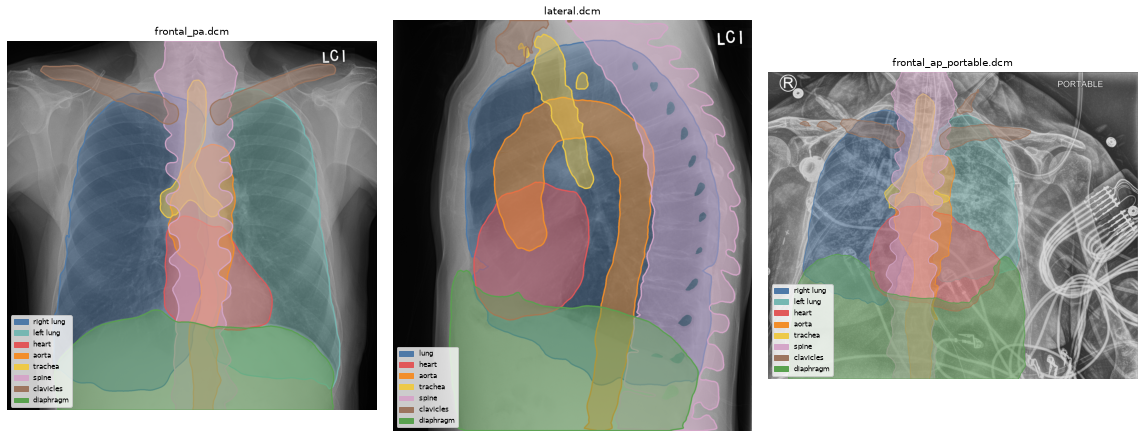

In [7]:
import matplotlib.pyplot as plt

def seg_masks(seg, wanted):
    labels = {s.SegmentNumber: s.SegmentLabel for s in seg.SegmentSequence}
    frames = seg.pixel_array
    out = {}
    for i, f in enumerate(seg.PerFrameFunctionalGroupsSequence):
        name = labels[f.SegmentIdentificationSequence[0].ReferencedSegmentNumber]
        if name in wanted:
            out[name] = frames[i]
    if "right lung" in out:          # frontal: show the sided lungs, not their union
        out.pop("lung", None)
    return {n: out[n] for n in wanted if n in out}

wanted = ["right lung", "left lung", "lung", "heart", "aorta", "trachea", "spine", "clavicles", "diaphragm"]
fig, ax = plt.subplots(1, 3, figsize=(16, 6))
for a, p in zip(ax, dicoms):
    s = hd.seg.segread(os.path.join(results[p], "seg.dcm"))
    overlay(a, display_image(p), seg_masks(s, wanted), title=os.path.basename(p))
plt.tight_layout()

## Read the Structured Report

Each landmark is a measurement group with its finding site, a name and an image-coordinate POINT on the source image; the measurements are numeric items with UCUM units.

In [8]:
sr = pydicom.dcmread(os.path.join(results[src], "landmarks_sr.dcm"))
print(sr.SOPClassUID.name, "|", sr.SeriesDescription)

points, numbers = [], []
def walk(items):
    for it in items:
        if it.ValueType == "CONTAINER" and it.ConceptNameCodeSequence[0].CodeMeaning == "Measurement Group":
            site = next((c.ConceptCodeSequence[0].CodeMeaning for c in it.ContentSequence
                         if c.ConceptNameCodeSequence[0].CodeMeaning == "Finding Site"), "")
            xy = next((c.GraphicData for c in it.ContentSequence if c.ValueType == "SCOORD"), None)
            if xy is not None:
                points.append((site, float(xy[0]), float(xy[1])))
        if it.ValueType == "NUM":
            mv = it.MeasuredValueSequence[0]
            numbers.append((it.ConceptNameCodeSequence[0].CodeMeaning, float(mv.NumericValue),
                            mv.MeasurementUnitsCodeSequence[0].CodeValue))
        if "ContentSequence" in it:
            walk(it.ContentSequence)
walk(sr.ContentSequence)
print(len(points), "landmark points, e.g.", points[:2])
for name, value, unit in numbers[:8]:
    print(f"  {name:28s} {value:9.2f} {unit}")

Comprehensive 3D SR Storage | CXAS anatomical landmarks
200 landmark points, e.g. [('vertebrae T1', 1456.98583984375, 171.51153564453125), ('vertebrae T1', 1104.2291259765625, 159.3044891357422)]
  ctr                               0.62 1
  cp_angle_max                     51.51 deg
  rib_level                         9.68 1
  dome_height                       0.31 1
  dome_dy                           0.03 1
  dome_dy_abs                       0.03 1
  rotation_index                    0.16 1
  cobb                              4.79 deg


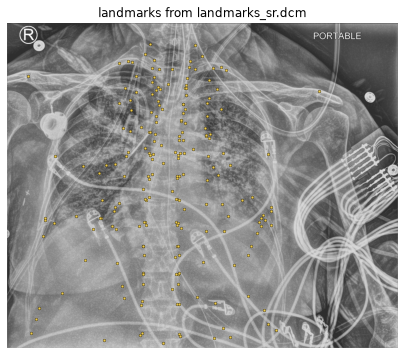

In [9]:
fig, ax = plt.subplots(figsize=(7, 6))
ax.imshow(display_image(src), cmap="gray"); ax.axis("off")
ax.scatter([p[1] for p in points], [p[2] for p in points], s=8, c="#edc948", edgecolors="black", linewidths=0.3)
ax.set_title("landmarks from landmarks_sr.dcm");

`result.json` holds everything in plain form (view, structures, spacing, measurements with units, all landmarks
with confidence and, with a pixel spacing, positions in mm).

**Citations.** IDC: Fedorov et al., *RadioGraphics* 43(12), 2023, https://doi.org/10.1148/rg.230180. The data
collections: see [`demo_utils.py`](demo_utils.py) or `idc.citations_from_selection(seriesInstanceUID=[...])`.

In [10]:
r = json.load(open(os.path.join(results[src], "result.json")))
{k: r[k] for k in ("view", "cxas_version", "model", "spacing", "landmark_min_confidence")}

{'view': 'frontal',
 'cxas_version': '0.1.2',
 'model': 'M2F_anatomy_v2',
 'spacing': {'row_mm': 0.139, 'col_mm': 0.139, 'source': 'PixelSpacing'},
 'landmark_min_confidence': 0.1}